In [7]:
import glob
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

In [8]:
# Load all fitness CSVs from Experiments/, grouped by parameter subfolder
EXPERIMENTS_DIR = "Creature Simulation/Experiments"

# groups: { "elite_count": { "1": Series, "2": Series, ... }, ... }
groups = defaultdict(dict)

for path in sorted(glob.glob(f"{EXPERIMENTS_DIR}/*/*.csv")):
    param = os.path.basename(os.path.dirname(path))   # subfolder = param name
    df = pd.read_csv(path)
    col = df.columns[0]                               # e.g. "elite_count=1"
    value = col.split("=", 1)[1] if "=" in col else os.path.splitext(os.path.basename(path))[0]
    groups[param][value] = df[col].reset_index(drop=True)

print(f"Found {sum(len(v) for v in groups.values())} run(s) across {len(groups)} experiment group(s):")
for param, runs in groups.items():
    print(f"  {param}: {sorted(runs.keys(), key=lambda x: float(x) if x.replace('.','',1).isdigit() else x)}")


Found 30 run(s) across 6 experiment group(s):
  elite_count: ['1', '2', '3', '4', '5']
  gene_count: ['5', '10', '15', '20', '25']
  grow_mutate_rate: ['0.05', '0.1', '0.15', '0.2', '0.25']
  max_links: ['10', '20', '30', '40', '50']
  point_mutate_rate: ['0.05', '0.1', '0.15', '0.20', '0.25']
  shrink_mutate_rate: ['0.05', '0.1', '0.15', '0.20', '0.25']


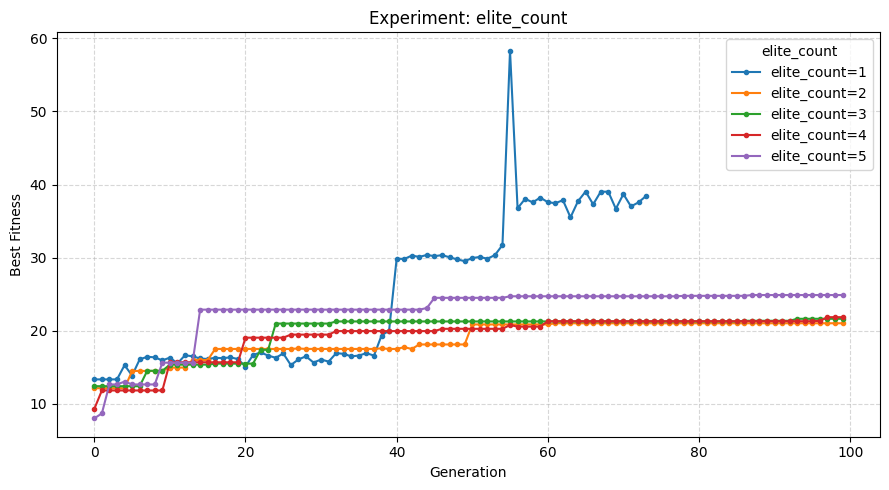

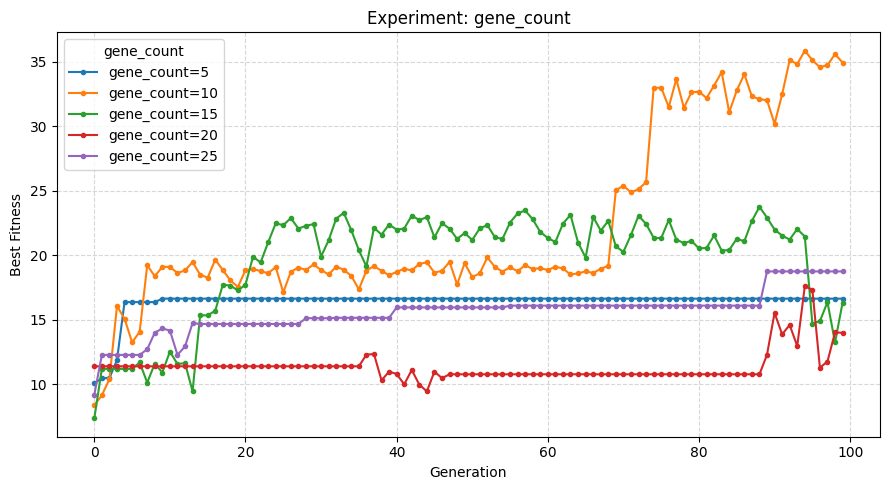

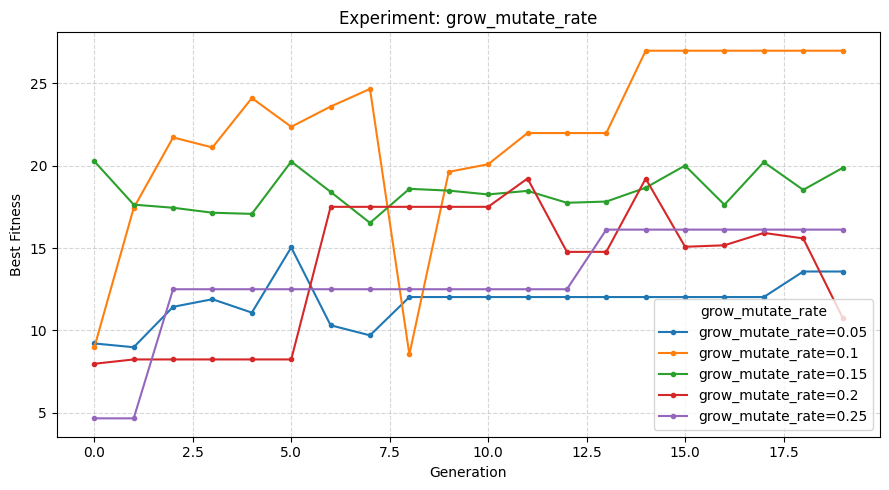

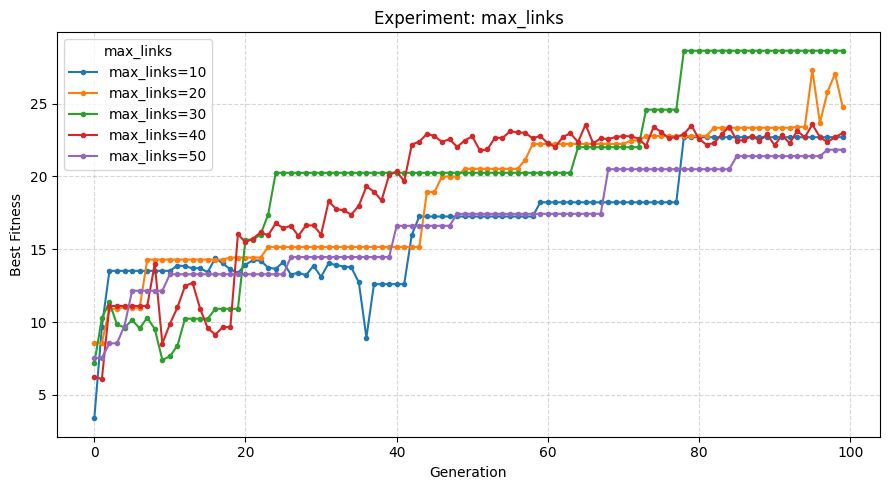

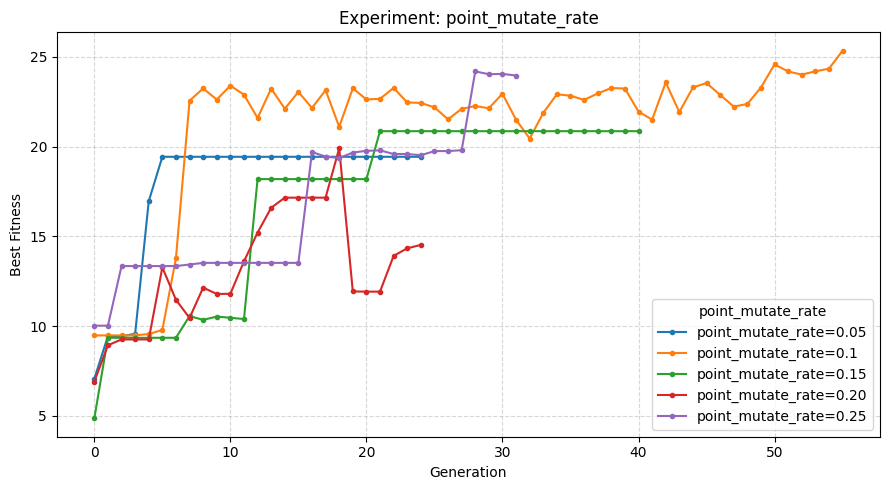

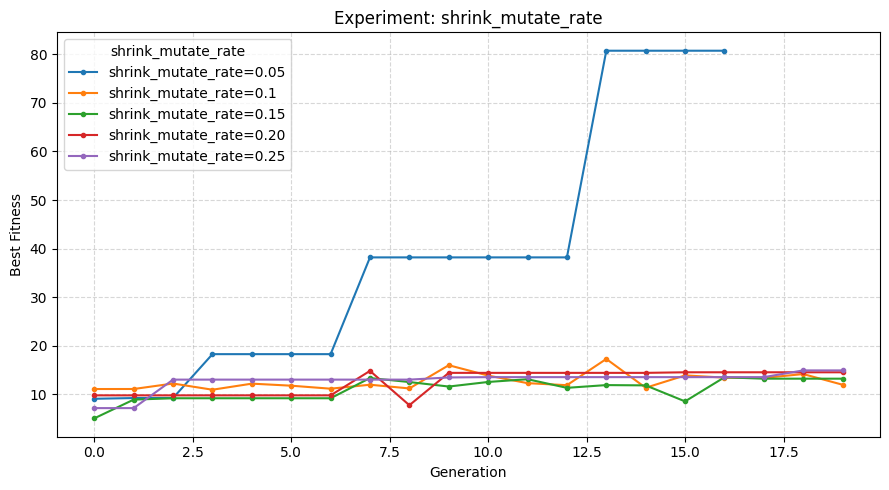

In [ ]:
# One polished figure per experiment group
import os
os.makedirs("report_figures", exist_ok=True)

for param, runs in groups.items():
    if not runs:
        continue

    fig, ax = plt.subplots(figsize=(9, 5))
    sorted_runs = sorted(runs.items(), key=lambda x: (float(x[0]) if x[0].replace('.','',1).isdigit() else x[0]))

    for value, series in sorted_runs:
        ax.plot(series.index, series.values, marker="o", markersize=3, linewidth=1.5, label=f"{param}={value}")

    ax.set_title(f"Best Fitness over Generations — varying {param}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Generation", fontsize=11)
    ax.set_ylabel("Best Fitness", fontsize=11)
    ax.legend(title=param, fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig(f"report_figures/{param}.png", dpi=150)
    plt.show()
    print(f"Saved: report_figures/{param}.png")


In [10]:
# Summary table per experiment group
for param, runs in groups.items():
    if not runs:
        continue

    sorted_runs = sorted(runs.items(), key=lambda x: (float(x[0]) if x[0].replace('.','',1).isdigit() else x[0]))

    rows = []
    for value, series in sorted_runs:
        rows.append({
            param:          value,
            "Generations":  len(series),
            "Max Fitness":  round(series.max(), 3),
            "Final Fitness": round(series.iloc[-1], 3),
            "Best Gen":     int(series.idxmax()),
        })

    df_summary = pd.DataFrame(rows).set_index(param)
    print(f"\n{'='*50}")
    print(f"  Experiment: {param}")
    print(f"{'='*50}")
    display(df_summary)



  Experiment: elite_count


,Generations,Max Fitness,Final Fitness,Best Gen
elite_count,,,,
1,74,58.309,38.432,55
2,100,21.015,21.015,61
3,100,21.626,21.626,93
4,100,21.848,21.848,97
5,100,24.877,24.877,87



  Experiment: gene_count


,Generations,Max Fitness,Final Fitness,Best Gen
gene_count,,,,
5,100,16.650,16.650,9
10,100,35.868,34.953,94
15,100,23.768,16.342,88
20,100,17.608,13.999,94
25,100,18.759,18.759,89



  Experiment: grow_mutate_rate


,Generations,Max Fitness,Final Fitness,Best Gen
grow_mutate_rate,,,,
0.05,20,15.040,13.578,5
0.1,20,26.989,26.989,14
0.15,20,20.275,19.869,0
0.2,20,19.226,10.780,11
0.25,20,16.121,16.121,13


... (2 outputs left out)


  Experiment: point_mutate_rate


,Generations,Max Fitness,Final Fitness,Best Gen
point_mutate_rate,,,,
0.05,25,19.433,19.433,5
0.1,56,25.341,25.341,55
0.15,41,20.860,20.860,21
0.20,25,19.909,14.526,18
0.25,32,24.188,23.959,28



  Experiment: shrink_mutate_rate


,Generations,Max Fitness,Final Fitness,Best Gen
shrink_mutate_rate,,,,
0.05,17,80.747,80.747,13
0.1,20,17.290,11.983,13
0.15,20,13.515,13.230,16
0.20,20,14.833,14.547,7
0.25,20,14.934,14.934,18
